In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [27]:
df = pd.read_csv("C:/Users/THE KING/Downloads/HousingData.csv")

In [28]:
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2


In [29]:
# 1. Exploration
print("Dimensions :", df.shape)
print(df.head())
print(df.info())
print("\\nValeurs manquantes :\\n", df.isna().sum())
print("\\nStatistiques descriptives :\\n", df.describe().T)

Dimensions : (506, 14)
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD  TAX  PTRATIO  \
0  0.00632  18.0   2.31   0.0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07   0.0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07   0.0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18   0.0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18   0.0  0.458  7.147  54.2  6.0622    3  222     18.7   

        B  LSTAT  MEDV  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.63   2.94  33.4  
4  396.90    NaN  36.2  
<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     486 non-null    float64
 1   ZN       486 non-null    float64
 2   INDUS    486 non-null    float64
 3   CHAS     486 non-null    float64
 4   NOX      506 non-nu

In [30]:
# 2. Nettoyage : médiane pour variables numériques, mode pour CHAS
data = df.copy()
for col in data.columns:
    if data[col].isna().any():
        if col == "CHAS":
            data[col] = data[col].fillna(data[col].mode()[0])
        else:
            data[col] = data[col].fillna(data[col].median())

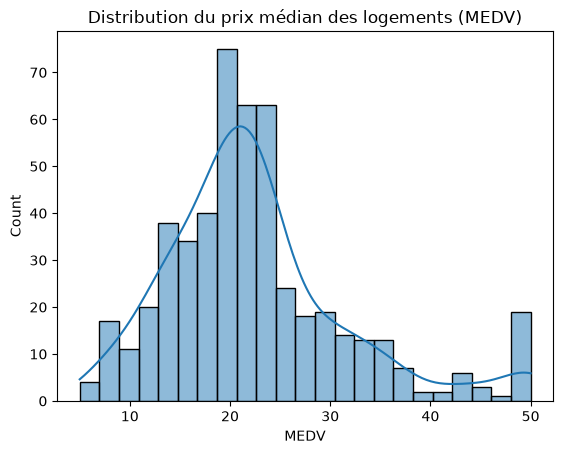

In [31]:
# 3. Distribution de la variable cible
sns.histplot(data["MEDV"], kde=True)
plt.title("Distribution du prix médian des logements (MEDV)")
plt.show()

\nCorrélations avec MEDV :\n MEDV       1.000000
RM         0.695360
ZN         0.362292
B          0.333461
DIS        0.249929
CHAS       0.183844
AGE       -0.377572
RAD       -0.381626
CRIM      -0.383895
NOX       -0.427321
TAX       -0.468536
INDUS     -0.476394
PTRATIO   -0.507787
LSTAT     -0.723093
Name: MEDV, dtype: float64


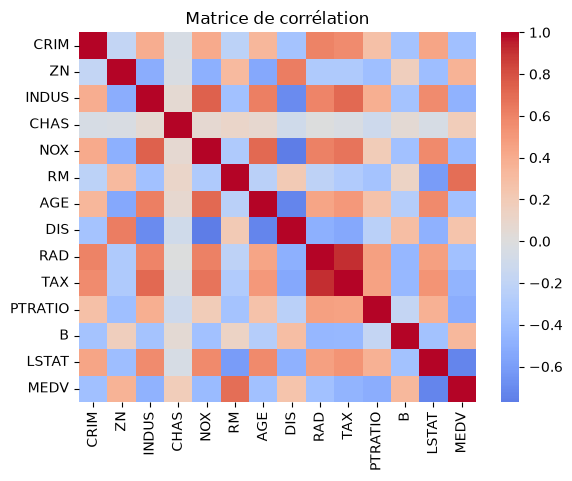

In [32]:
# 4. Corrélations
corr = data.corr(numeric_only=True)
print("\\nCorrélations avec MEDV :\\n", corr["MEDV"].sort_values(ascending=False))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.show()

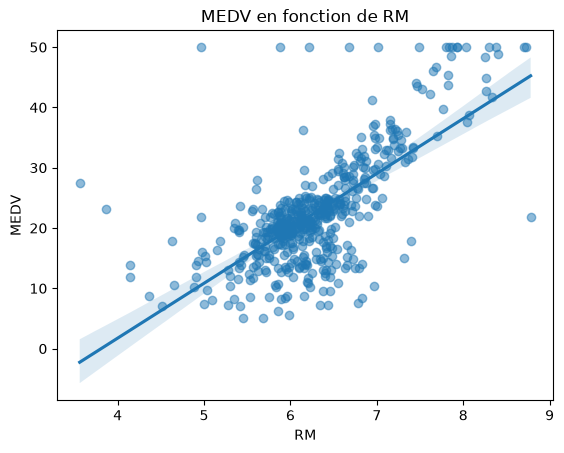

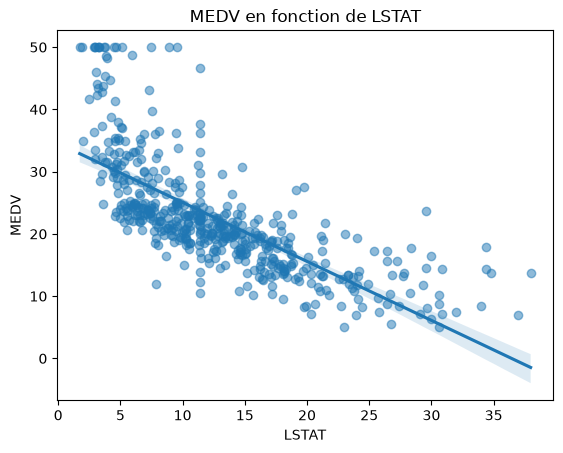

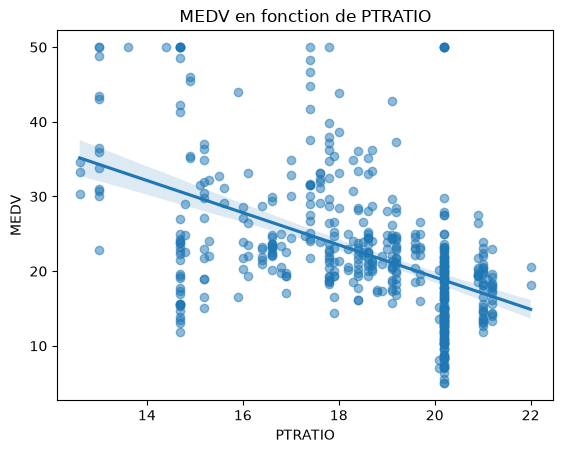

In [33]:
# 5. Relations avec MEDV
for col in ["RM", "LSTAT", "PTRATIO"]:
    sns.regplot(data=data, x=col, y="MEDV", scatter_kws={"alpha": 0.5})
    plt.title(f"MEDV en fonction de {col}")
    plt.show()

In [34]:
# 6. Valeurs aberrantes avec la règle IQR
for col in data.select_dtypes(include=np.number):
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((data[col] < q1 - 1.5*iqr) | (data[col] > q3 + 1.5*iqr)).sum()
    print(f"{col}: {n} valeurs aberrantes potentielles")

CRIM: 81 valeurs aberrantes potentielles
ZN: 126 valeurs aberrantes potentielles
INDUS: 0 valeurs aberrantes potentielles
CHAS: 34 valeurs aberrantes potentielles
NOX: 0 valeurs aberrantes potentielles
RM: 30 valeurs aberrantes potentielles
AGE: 0 valeurs aberrantes potentielles
DIS: 5 valeurs aberrantes potentielles
RAD: 0 valeurs aberrantes potentielles
TAX: 0 valeurs aberrantes potentielles
PTRATIO: 15 valeurs aberrantes potentielles
B: 77 valeurs aberrantes potentielles
LSTAT: 12 valeurs aberrantes potentielles
MEDV: 40 valeurs aberrantes potentielles


In [35]:
# 7. Exemple de requêtes métier
print("\\nLogements dont MEDV > 30 :")
print(data.loc[data["MEDV"] > 30, ["RM", "LSTAT", "MEDV"]].head(10))
print("\\nMoyenne de MEDV par CHAS :")
print(data.groupby("CHAS")["MEDV"].mean())


\nLogements dont MEDV > 30 :
       RM  LSTAT  MEDV
2   7.185   4.03  34.7
3   6.998   2.94  33.4
4   7.147  11.43  36.2
39  6.595   4.32  30.8
40  7.024   1.98  34.9
55  7.249   4.81  35.4
57  6.816   3.95  31.6
64  7.104   8.05  33.0
97  8.069   4.21  38.7
98  7.820   3.57  43.8
\nMoyenne de MEDV par CHAS :
CHAS
0.0    22.079449
1.0    28.826471
Name: MEDV, dtype: float64
